# Анализ рынка видеоигр

Учебный проект на исторических данных до 2016 года. Данные не включены в репозиторий; см. README. Эта версия очищена от истории ревью. После правок статистических тестов ноутбук нужно выполнить целиком, чтобы обновить результаты и графики.

# Сборный проект

Описание:

Вы работаете в интернет-магазине «Стримчик», который продаёт по всему миру компьютерные игры. Из открытых источников доступны исторические данные о продажах игр, оценки пользователей и экспертов, жанры и платформы (например, Xbox или PlayStation).

Необходимо выявить определяющие успешность игры закономерности. Это позволит сделать ставку на потенциально популярный продукт и спланировать рекламные кампании на 2017 год (сейчас декабрь 2016)

**Описание данных:**
- Name — название игры
- Platform — платформа
- Year_of_Release — год выпуска
- Genre — жанр игры
- NA_sales — продажи в Северной Америке (миллионы проданных копий)
- EU_sales — продажи в Европе (миллионы проданных копий)
- JP_sales — продажи в Японии (миллионы проданных копий)
- Other_sales — продажи в других странах (миллионы проданных копий)
- Critic_Score — оценка критиков (максимум 100)
- User_Score — оценка пользователей (максимум 10)
- Rating — рейтинг от организации ESRB (англ. Entertainment Software Rating Board). Эта ассоциация, определяющая возрастной рейтинг компьютерных игр. ESRB оценивает игровой контент и присваивает ему подходящую возрастную категорию, например, «Для взрослых», «Для детей младшего возраста» или «Для подростков».

**План работ:**
- Подготовить данные и обработать их: найти пропуски, дубликаты, добавить новый столбец, привести данные в корректный вид
- Проанализировать: как менялось количество издаваемых игр из года в год, как менялись продажи по платформам, выявить лидеров (топ-5), определить актуальный период и рассмотреть его более плотно + оценить влияние оценок пользователей и критиков на продажи
- Составить портрет пользователя в основных регионах (Северная Америка, Европа, Япония)
- Проверить гипотезы о рейтингах платформ Xbox и PC, а также жанров Action и Sports
- Составить вывод

## Импорт библиотек и загрузка данных

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats as st

In [2]:
from pathlib import Path

DATA_PATHS = [Path("data/games.csv")]
DATA_URL = "https://code.s3.yandex.net/datasets/games.csv"

for path in DATA_PATHS:
    if path.exists():
        df = pd.read_csv(path)
        break
else:
    raise FileNotFoundError("Поместите games.csv в папку data/")

Изучим данные

In [3]:
df.shape

(16715, 11)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [5]:
# выведем 10 случайных строк, чтобы посмотреть на общую структуру
df.sample(5)

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
8116,Squeeballs Party,Wii,2009.0,Puzzle,0.17,0.00,0.00,0.01,59.0,tbd,E10+
942,Pinball,NES,1984.0,Action,0.80,0.19,0.83,0.03,NaN,NaN,NaN
4632,Black,XB,2006.0,Shooter,0.31,0.09,0.00,0.01,77.0,8,M
10680,Micro Machines V3,PS,1997.0,Racing,0.06,0.04,0.00,0.01,NaN,NaN,NaN
14780,Otome wa Oanesama ni Koi Shiteru Portable: 2-J...,PSP,2011.0,Adventure,0.00,0.00,0.03,0.00,NaN,NaN,NaN


In [6]:
# проверим на пропуски
df.isna().sum()

Name                  2
Platform              0
Year_of_Release     269
Genre                 2
NA_sales              0
EU_sales              0
JP_sales              0
Other_sales           0
Critic_Score       8578
User_Score         6701
Rating             6766
dtype: int64

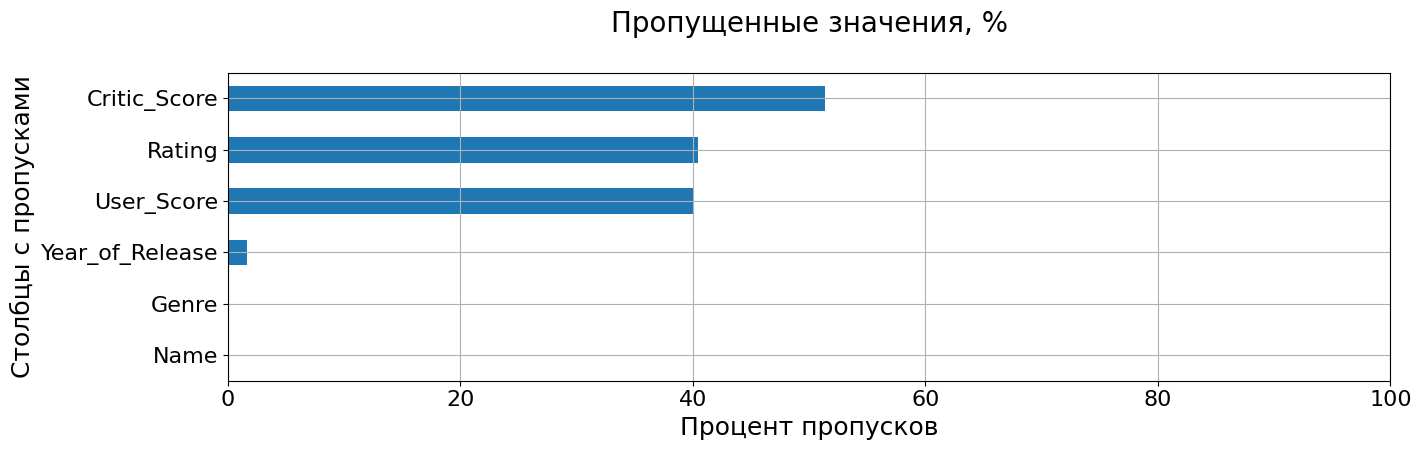

In [7]:
def pass_value_barh(df):
    try:
        (
            (df.isna().mean()*100)
            .to_frame()
            .rename(columns = {0:'space'})
            .query('space > 0')
            .sort_values(by = 'space', ascending = True)
            .plot(kind = 'barh', figsize = (15,4), legend = False, fontsize = 16, grid=True)
        );
        plt.title('Пропущенные значения, %' + "\n", fontsize=20, color='black')
        plt.xlabel('Процент пропусков', fontsize=18)
        plt.ylabel('Столбцы с пропусками', fontsize=18)
        plt.xlim(0, 100)   
    except:
        print('пропусков не осталось, или произошла ошибка в первой части функции ')
        
pass_value_barh(df)

In [8]:
# проверим на дубликаты
df.duplicated().sum()

np.int64(0)

In [9]:
df[df.duplicated(subset=['Name', 'Platform', 'Year_of_Release'])]

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
14244,NaN,GEN,1993.0,NaN,0.0,0.00,0.03,0.0,NaN,NaN,NaN
16230,Madden NFL 13,PS3,2012.0,Sports,0.0,0.01,0.00,0.0,83.0,5.5,E


Выводы:
- Всего в датафреме 16715 строк
- Дубликатов не обнаружено
- Есть пропуски в 6 столбцах, которые будут обработаны дальше
- Обнаружено 2 неявных дубликата. Будут обработаны ниже - п. 2.3 и 2.4



## Подготовка данных


### Нижний регистр

In [10]:
# приведем названия столбцов к нижнему регистру
df.columns = df.columns.str.lower()

# то же самое сделаем и со строками в name, platform и genre
df['name'] = df['name'].str.lower()
df['platform'] = df['platform'].str.lower()
df['genre'] = df['genre'].str.lower()


# проверим
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,wii sports,wii,2006.0,sports,41.36,28.96,3.77,8.45,76.0,8,E
1,super mario bros.,nes,1985.0,platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,mario kart wii,wii,2008.0,racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,wii sports resort,wii,2009.0,sports,15.61,10.93,3.28,2.95,80.0,8,E
4,pokemon red/pokemon blue,gb,1996.0,role-playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


### Преобразуем данные

In [11]:
# для корректного отображения приведем столблец year_of_release к типу int
df['year_of_release'] = df['year_of_release'].astype('Int64')

In [12]:
# проверим изменения в типах данных
df.dtypes

name                object
platform            object
year_of_release      Int64
genre               object
na_sales           float64
eu_sales           float64
jp_sales           float64
other_sales        float64
critic_score       float64
user_score          object
rating              object
dtype: object

In [13]:
df.query('user_score == "tbd"')

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
119,zumba fitness,wii,2010,sports,3.45,2.59,0.0,0.66,NaN,tbd,E
301,namco museum: 50th anniversary,ps2,2005,misc,2.08,1.35,0.0,0.54,61.0,tbd,E10+
520,zumba fitness 2,wii,2011,sports,1.51,1.03,0.0,0.27,NaN,tbd,T
645,udraw studio,wii,2010,misc,1.65,0.57,0.0,0.20,71.0,tbd,E
657,frogger's adventures: temple of the frog,gba,<NA>,adventure,2.15,0.18,0.0,0.07,73.0,tbd,E
...,...,...,...,...,...,...,...,...,...,...,...
16695,planet monsters,gba,2001,action,0.01,0.00,0.0,0.00,67.0,tbd,E
16697,bust-a-move 3000,gc,2003,puzzle,0.01,0.00,0.0,0.00,53.0,tbd,E
16698,mega brain boost,ds,2008,puzzle,0.01,0.00,0.0,0.00,48.0,tbd,E
16704,plushees,ds,2008,simulation,0.01,0.00,0.0,0.00,NaN,tbd,E


В столбце user_score были обнаружены оценки tbd (2424 строки) - это инструмент, который используется для оценки или маркировки чего-либо, когда точные данные либо еще не определены, либо находятся в процессе составления.

Поэтому заменим значения на NaN

In [14]:
df['user_score'] = df['user_score'].apply(pd.to_numeric, errors='coerce')

In [15]:
df.query('user_score.isna()')

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
1,super mario bros.,nes,1985,platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
4,pokemon red/pokemon blue,gb,1996,role-playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
5,tetris,gb,1989,puzzle,23.20,2.26,4.22,0.58,NaN,NaN,NaN
9,duck hunt,nes,1984,shooter,26.93,0.63,0.28,0.47,NaN,NaN,NaN
10,nintendogs,ds,2005,simulation,9.05,10.95,1.93,2.74,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
16710,samurai warriors: sanada maru,ps3,2016,action,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16711,lma manager 2007,x360,2006,sports,0.00,0.01,0.00,0.00,NaN,NaN,NaN
16712,haitaka no psychedelica,psv,2016,adventure,0.00,0.00,0.01,0.00,NaN,NaN,NaN
16713,spirits & spells,gba,2003,platform,0.01,0.00,0.00,0.00,NaN,NaN,NaN


In [16]:
# проверим
df.head(120)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,wii sports,wii,2006,sports,41.36,28.96,3.77,8.45,76.0,8.0,E
1,super mario bros.,nes,1985,platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,mario kart wii,wii,2008,racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,wii sports resort,wii,2009,sports,15.61,10.93,3.28,2.95,80.0,8.0,E
4,pokemon red/pokemon blue,gb,1996,role-playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
115,crash bandicoot,ps,1996,platform,3.23,2.35,0.94,0.30,NaN,NaN,NaN
116,just dance 4,wii,2012,misc,4.05,2.16,0.00,0.55,74.0,7.3,E10+
117,gears of war 2,x360,2008,shooter,4.15,1.90,0.06,0.64,93.0,7.7,M
118,uncharted 3: drake's deception,ps3,2011,action,2.77,2.75,0.19,1.03,92.0,8.3,T


Теперь типы данных указаны верно

### Проверим на неявные дубликаты

In [17]:
# неявных дубликата - 2
df[df.duplicated(subset=['name', 'platform', 'year_of_release'])]

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
14244,NaN,gen,1993,NaN,0.0,0.00,0.03,0.0,NaN,NaN,NaN
16230,madden nfl 13,ps3,2012,sports,0.0,0.01,0.00,0.0,83.0,5.5,E


In [18]:
# Сначала удаляем строки без названия игры, затем устраняем повторные записи
# одной игры на одной платформе в одном году. Не используем фиксированный индекс строки.
df = df.dropna(subset=["name"])
df = df.drop_duplicates(subset=["name", "platform", "year_of_release"], keep="first")

In [19]:
# проверка
df.duplicated(['name', 'platform', 'year_of_release']).sum()

np.int64(0)

### Обработаем пропуски

In [20]:
df.isna().sum()

name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating             6764
dtype: int64

Возможные причины пропусков:

- Человеческий фактор: заполняющие могли по какой-либо причине пропустить поля. в том числе - целенаправленно;
- Технические сбои: ошибки при выгрузке и/или при переносе из одной базы данных в другую;
- Ошибки в коде. пример: существует закономерность, что в столбце A все значения должны быть равны 0, и в таком случае в столбце Z все значения будут равны 0. Но по какой-то причине в столбце A появились значения != 0, и как следствие - ошибки в столбце Z (т.е. пропуски
- Пропуски в рейтинге могли еще появиться, потому что организация ESRB была основана в 1994, соответственно до этого для рейтинга могли использовать другие обозначения

In [21]:
df.query('name.isna()')

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating


In [22]:
# Количество пропусков в name - 2. Это 0,01% от всего датафрейма. Данные по ним практически отсутствуют
# Поэтому удаляем эти строки
df = df.dropna(subset=['name'])

In [23]:
# финальная проверка на дубликаты
df.duplicated(['name', 'platform', 'year_of_release']).sum()

np.int64(0)

Строки с пропусками в столбце year_of_release не удаляем, так как это может повлиять на дальнейший анализ. Также, мы не можем заполнить тут пропуски данными по релизу на другие платформы, так как это не будет корректно. Например, одна и та же игра на X360 и PS4 может выходить в разные годы

Так же и по столбцам critic_score, user_score, rating: мы не можем заполнить пропуски, так как это может повлиять на дальнейшую работу с данными. Поэтому оставляем эти столбцы в исходном виде

### Суммарные продажи во всех регионах

In [24]:
# Суммарные продажи во всех регионах, млн копий
df["total_sales"] = df[["na_sales", "eu_sales", "jp_sales", "other_sales"]].sum(axis=1)
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,wii sports,wii,2006,sports,41.36,28.96,3.77,8.45,76.0,8.0,E,82.54
1,super mario bros.,nes,1985,platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN,40.24
2,mario kart wii,wii,2008,racing,15.68,12.76,3.79,3.29,82.0,8.3,E,35.52
3,wii sports resort,wii,2009,sports,15.61,10.93,3.28,2.95,80.0,8.0,E,32.77
4,pokemon red/pokemon blue,gb,1996,role-playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN,31.38


## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

## Исследовательский анализ

### Количество игр в разные годы


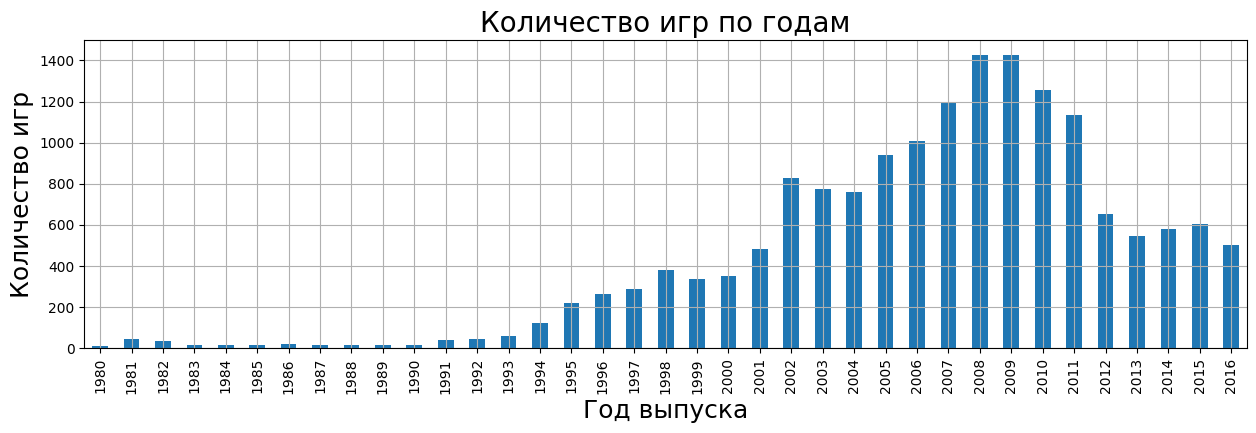

In [25]:
# построим график и посмотрим, как менялось количество выпускаемых игр из года в год
(
df
    .pivot_table(index='year_of_release', values='platform', aggfunc='count')
    .plot(kind='bar', figsize=(15, 4), legend=False, grid=True)
);
plt.title('Количество игр по годам', fontsize=20, color='black')
plt.xlabel('Год выпуска', fontsize=18)
plt.ylabel('Количество игр', fontsize=18);

#### Вывод:
- Больше всего игр выпускалось в 2008-2009 годах
- Насколько важны даныне за все периоды, мы узнаем позже, когда посмотрим на цикл жизни платформ

### Как менялись продажи по платформам

#### Всего продаж

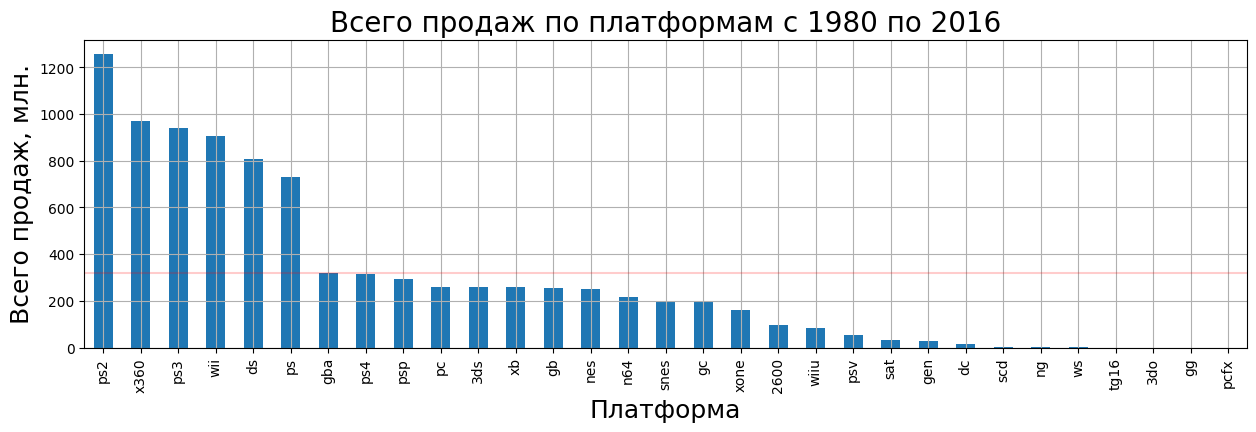

Наиболее успешные платформы:


,total_sales
platform,
ps2,1255.77
x360,971.42
ps3,939.64
wii,907.51
ds,806.12
ps,730.86


In [26]:
# построим график
(
df
    .pivot_table(index='platform', values='total_sales', aggfunc='sum')
    .sort_values(by='total_sales', ascending=False)
    .plot(kind='bar', figsize=(15, 4), legend=False, grid=True)
);
plt.title('Всего продаж по платформам с 1980 по 2016', fontsize=20, color='black')
plt.xlabel('Платформа', fontsize=18)
plt.ylabel('Всего продаж, млн.', fontsize=18)
plt.axhline(y=317.85, color='red', linestyle='-', alpha=0.2)
plt.show()

# выделим 6 наибоелее успешных платформ
print('Наиболее успешные платформы:')
display(
df
    .pivot_table(index='platform', values='total_sales', aggfunc='sum')
    .sort_values(by='total_sales', ascending=False)
    .head(6)
)

#### Распределение топ-6 по годам

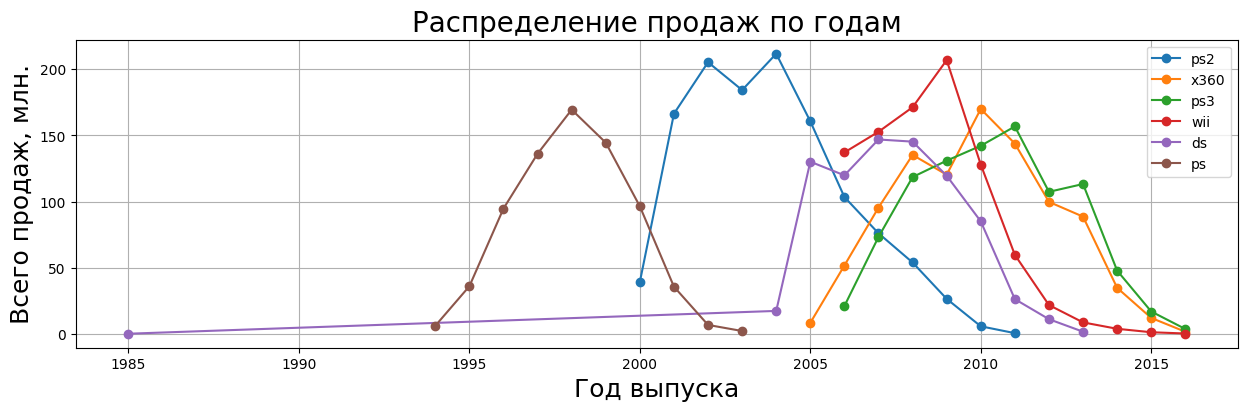

In [27]:
# создаем список топ-6 платформ
top_platforms = ['ps2', 'x360', 'ps3', 'wii', 'ds', 'ps']

# задаем размеры графика, на котором будут изображения все 6 платформ
fig, ax = plt.subplots(figsize=(15, 4))

# проходим циклом for по каждой платформе и строим график
for p in top_platforms:
    p_data = df.query('platform == @p').pivot_table(index='year_of_release', values='total_sales', aggfunc='sum')
    p_data.plot(kind='line', ax=ax, legend=False, grid=True, style='o-')
    
# подпись к графике и осям
plt.title('Распределение продаж по годам', fontsize=20, color='black')
plt.xlabel('Год выпуска', fontsize=18)
plt.ylabel('Всего продаж, млн.', fontsize=18)
plt.legend(top_platforms)

plt.show()

In [28]:
# на графике обнаружен подозрительный "хвост", идущий с 1985. Посмотрим на него
# возьмем период до 2005, так как с этого года наблюдается рост

df.query('platform == "ds" and year_of_release < 2004')

/tmp/ipykernel_1805/4280933123.py:4: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  df.query('platform == "ds" and year_of_release < 2004')


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
15957,strongest tokyo university shogi ds,ds,1985,action,0.0,0.0,0.02,0.0,NaN,NaN,NaN,0.02


Найдена всего одна строка - игра от 1985 года. Выпускалась только на рынок JP, количество продаж небольшое - всего 20 000. Поэтому принимаем решение удалить строку

In [29]:
# удаляем строку
df = df.drop([15957])

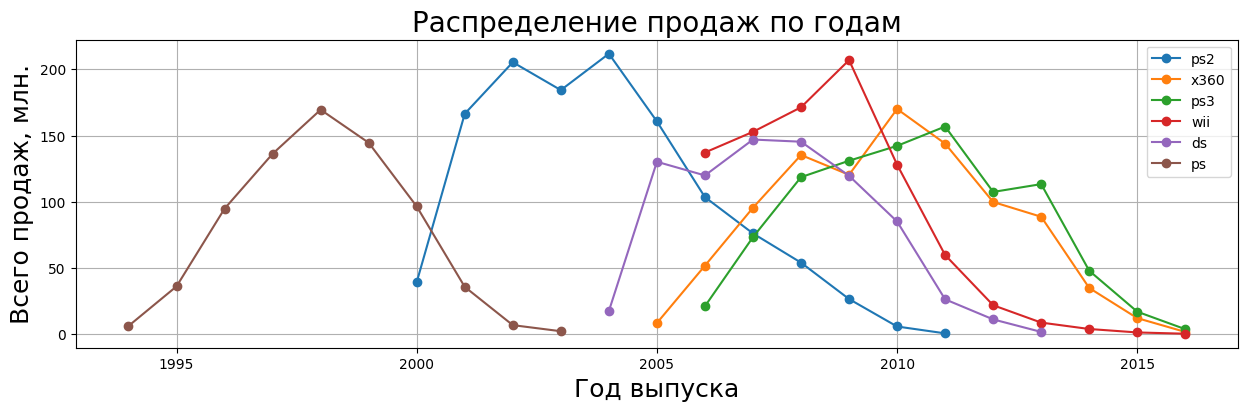

In [30]:
# повторно строим график

fig, ax = plt.subplots(figsize=(15, 4))

for p in top_platforms:
    p_data = df.query('platform == @p').pivot_table(index='year_of_release', values='total_sales', aggfunc='sum')
    p_data.plot(kind='line', ax=ax, legend=False, grid=True, style='o-')
    
plt.title('Распределение продаж по годам', fontsize=20, color='black')
plt.xlabel('Год выпуска', fontsize=18)
plt.ylabel('Всего продаж, млн.', fontsize=18)
plt.legend(top_platforms)

plt.show()

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

### Лидеры по продажам за 4 года

#### Топ-5 c 2012

In [31]:
# сделаем срез за актуальный период (с 2012)
act_df = df.query('year_of_release >= 2012')

/tmp/ipykernel_1805/2672788893.py:2: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  act_df = df.query('year_of_release >= 2012')


In [32]:
# зададими функцию, чтобы упросить впоследствии создание сводных таблиц топ-5 по актуальному пероиду

def act_piv_top(dataframe = [], index = [], val = [], aggfunc = []):
    return (dataframe
            .pivot_table(index=index, values=val, aggfunc=aggfunc)
            .sort_values(by=val, ascending=False)
            .head())

In [33]:
(act_df
            .pivot_table(index='platform', values='total_sales', aggfunc='sum')
            .sort_values(by='total_sales', ascending=False)
)

,total_sales
platform,
ps4,314.14
ps3,288.78
x360,236.54
3ds,194.61
xone,159.32
wiiu,82.19
pc,62.65
psv,49.18
wii,35.37


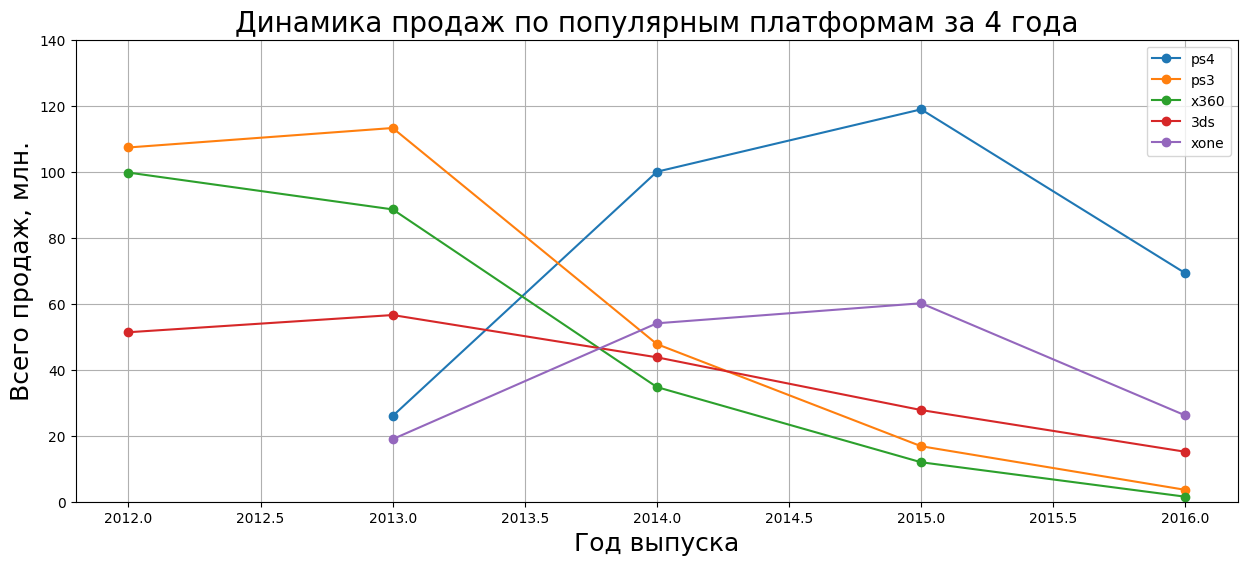

In [34]:
top5_2012 = act_df.groupby('platform')['total_sales'].sum().nlargest(5).index.tolist()

# построим график по топ-5 за последние 4 года
fig, ax = plt.subplots(figsize=(15, 6))

for i in top5_2012:
    i_data = act_df.query('platform == @i').pivot_table(index='year_of_release', values='total_sales', aggfunc='sum')
    i_data.plot(kind='line', ax=ax, legend=False, grid=True, style='o-')
    
plt.title('Динамика продаж по популярным платформам за 4 года', fontsize=20, color='black')
plt.xlabel('Год выпуска', fontsize=18)
plt.ylabel('Всего продаж, млн.', fontsize=18)
plt.legend(top5_2012)
plt.ylim(0, 140)

plt.show()

Выводы:

Исходя из данных на графике, видно, что роста по каким-либо платформам не наблюдается. Скорее, наоборот продажи по всем платформам идут на спад. Легче других переживают этот спад ps4

In [35]:
# сделаем срез за актуальный период (с 2013)
df_last3_act = df.query('2013 <= year_of_release <= 2016')

/tmp/ipykernel_1805/10399498.py:2: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  df_last3_act = df.query('2013 <= year_of_release <= 2016')


In [36]:
(df_last3_act
            .pivot_table(index='platform', values='total_sales', aggfunc='sum')
            .sort_values(by='total_sales', ascending=False)
)

,total_sales
platform,
ps4,314.14
ps3,181.43
xone,159.32
3ds,143.25
x360,136.80
wiiu,64.63
pc,39.43
psv,32.99
wii,13.66


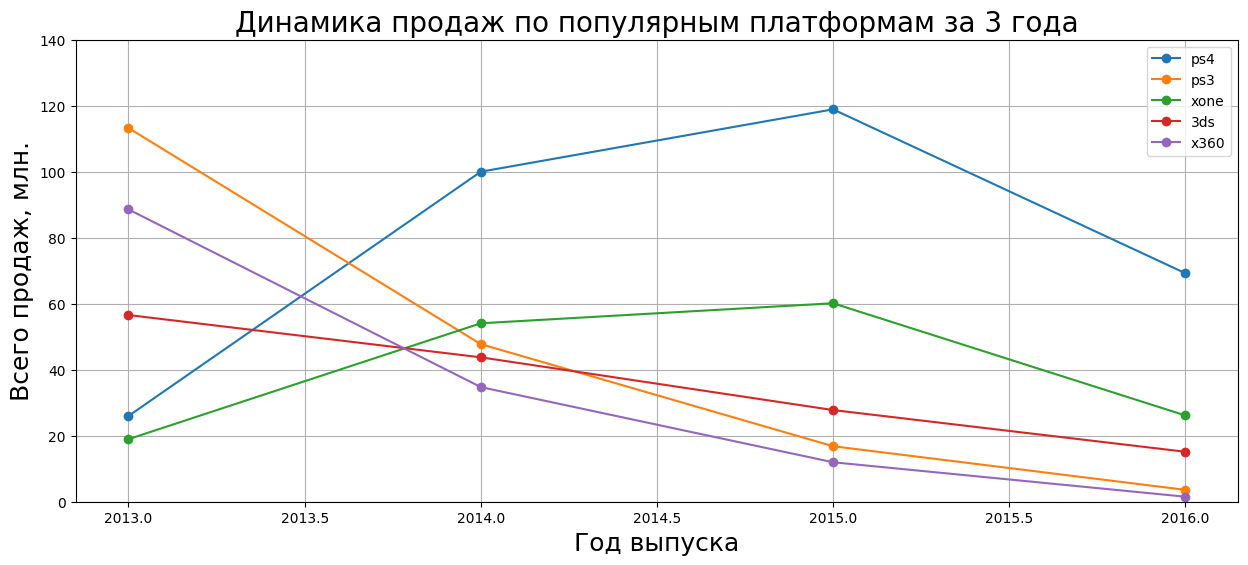

In [37]:
top5_20132016 = df_last3_act.groupby('platform')['total_sales'].sum().nlargest(5).index.tolist()

# построим график по топ-5 за последние 3 года: 2013 - 2015
fig, ax = plt.subplots(figsize=(15, 6))

for i in top5_20132016:
    i_data = df_last3_act.query('platform == @i').pivot_table(index='year_of_release', values='total_sales', aggfunc='sum')
    i_data.plot(kind='line', ax=ax, legend=False, grid=True, style='o-')
    
plt.title('Динамика продаж по популярным платформам за 3 года', fontsize=20, color='black')
plt.xlabel('Год выпуска', fontsize=18)
plt.ylabel('Всего продаж, млн.', fontsize=18)
plt.legend(top5_20132016)
plt.ylim(0, 140)

plt.show()

#### Глобальные продажи

In [38]:
# act_df['total_sales'].describe()

In [39]:
df_last3_act['total_sales'].describe()

count    2233.000000
mean        0.488442
std         1.235226
min         0.010000
25%         0.030000
50%         0.110000
75%         0.400000
max        21.050000
Name: total_sales, dtype: float64

In [40]:
"""# построим ящик с усами

fig, ax = plt.subplots(figsize=(15,8))

sns.boxplot(
    data=act_df,
    x='total_sales', 
    y='platform', 
    palette="light:#5A9"
)

plt.title('boxlot "Продажи по перспективным платформам"', fontsize=15)
plt.xlabel('Продажи', fontsize=12)
plt.ylabel('Платформа',fontsize=12)
plt.xlim(0, 3)
plt.axvline(x=0.25, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=0.75, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=1.25, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=1.75, color='grey', linestyle='-', alpha=0.2)

plt.grid(True)
plt.show()"""

'# построим ящик с усами\n\nfig, ax = plt.subplots(figsize=(15,8))\n\nsns.boxplot(\n    data=act_df,\n    x=\'total_sales\', \n    y=\'platform\', \n    palette="light:#5A9"\n)\n\nplt.title(\'boxlot "Продажи по перспективным платформам"\', fontsize=15)\nplt.xlabel(\'Продажи\', fontsize=12)\nplt.ylabel(\'Платформа\',fontsize=12)\nplt.xlim(0, 3)\nplt.axvline(x=0.25, color=\'grey\', linestyle=\'-\', alpha=0.2)\nplt.axvline(x=0.75, color=\'grey\', linestyle=\'-\', alpha=0.2)\nplt.axvline(x=1.25, color=\'grey\', linestyle=\'-\', alpha=0.2)\nplt.axvline(x=1.75, color=\'grey\', linestyle=\'-\', alpha=0.2)\n\nplt.grid(True)\nplt.show()'

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

/tmp/ipykernel_1805/3510875118.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


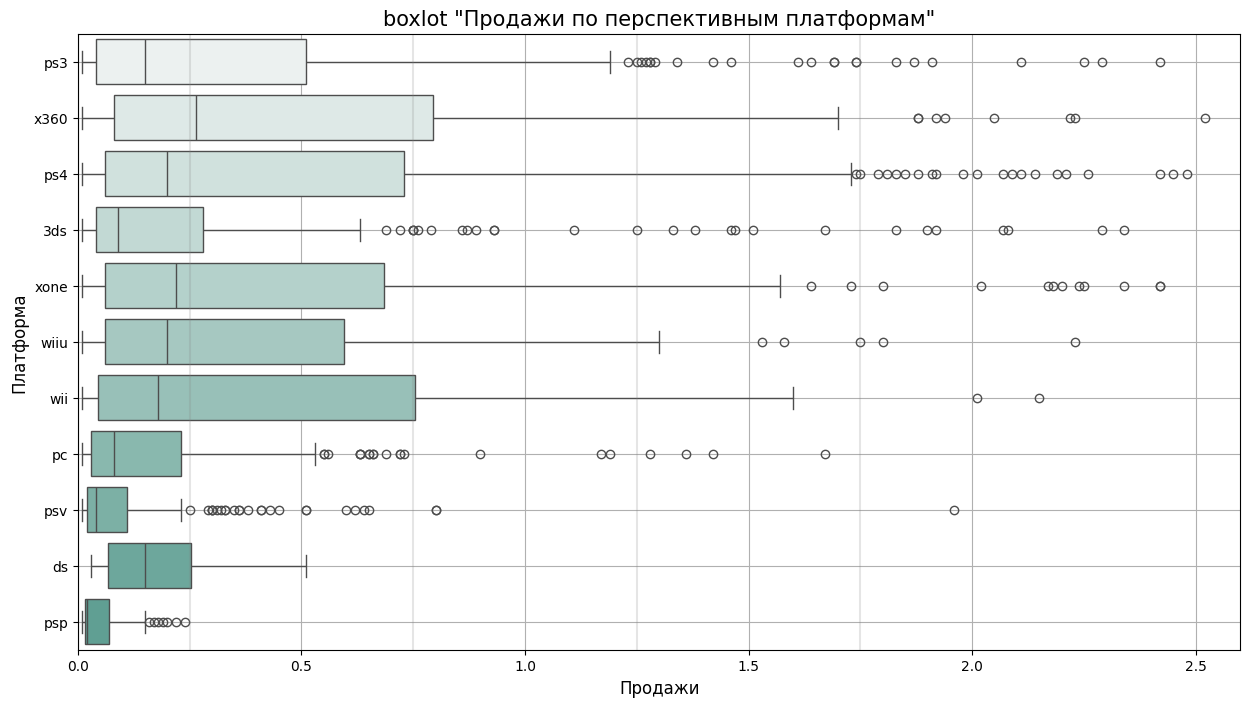

In [41]:
# построим ящик с усами

fig, ax = plt.subplots(figsize=(15,8))

sns.boxplot(
    data=df_last3_act,
    x='total_sales', 
    y='platform', 
    palette="light:#5A9"
)

plt.title('boxlot "Продажи по перспективным платформам"', fontsize=15)
plt.xlabel('Продажи', fontsize=12)
plt.ylabel('Платформа',fontsize=12)
plt.xlim(0, 2.6)
plt.axvline(x=0.25, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=0.75, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=1.25, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=1.75, color='grey', linestyle='-', alpha=0.2)

plt.grid(True)
plt.show()

/tmp/ipykernel_1805/964487895.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


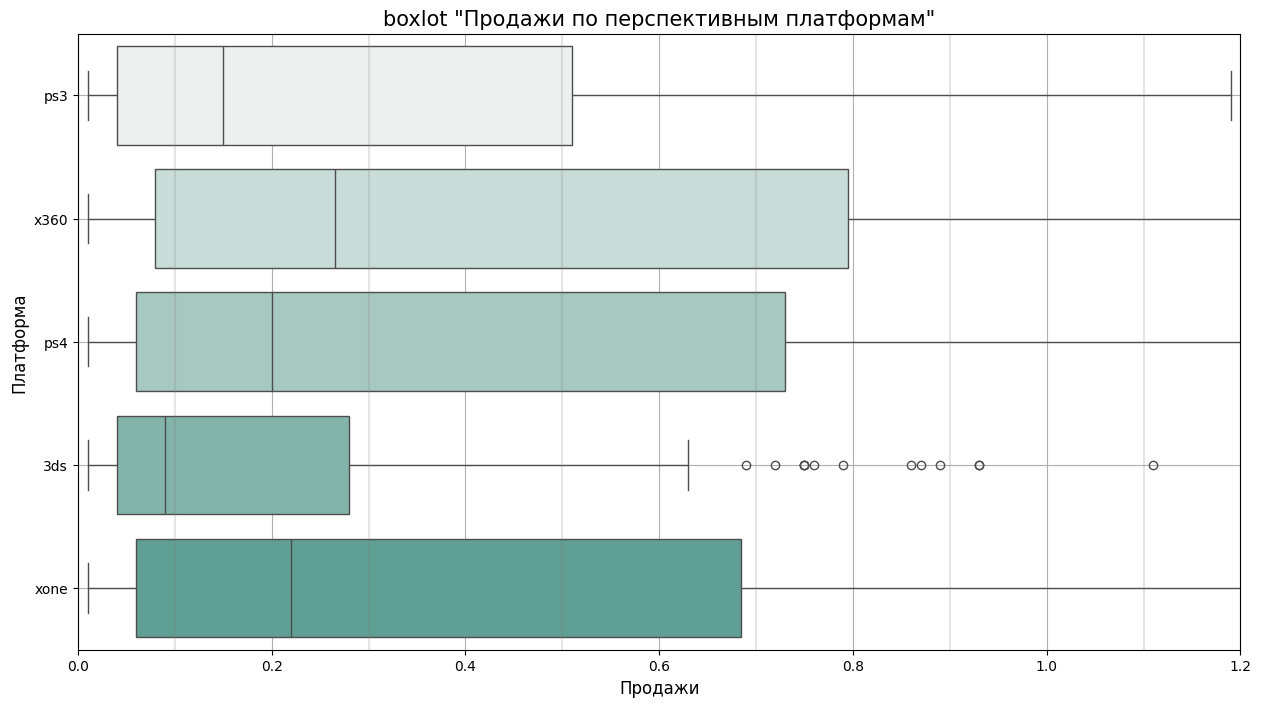

In [42]:
# Выведем топ-5 поближе

# используя метод nlargest, получим 5 лучших платформ в плане выручки. определим в переменную top5_consoles
top5_consoles = df_last3_act.groupby('platform')['total_sales'].sum().nlargest(5).index

fig, ax = plt.subplots(figsize=(15,8))

sns.boxplot(
    data=df_last3_act[df_last3_act['platform'].isin(top5_consoles)], # поиск по платформам в числе указанных в top5_consoles
    x='total_sales', 
    y='platform', 
    palette="light:#5A9"
)

plt.title('boxlot "Продажи по перспективным платформам"', fontsize=15)
plt.xlabel('Продажи', fontsize=12)
plt.ylabel('Платформа',fontsize=12)
plt.xlim(0, 1.2)
plt.axvline(x=0.1, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=0.3, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=0.5, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=0.7, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=0.9, color='grey', linestyle='-', alpha=0.2)
plt.axvline(x=1.1, color='grey', linestyle='-', alpha=0.2)

plt.grid(True)
plt.show()


### Влияние отзывов на продажи

Посмотрим, как влияют на продажи внутри популярных платформ отзывы пользователей и критиков. Построим диаграмму рассеяния и посчитаем корреляцию между отзывами и продажами

#### ps4

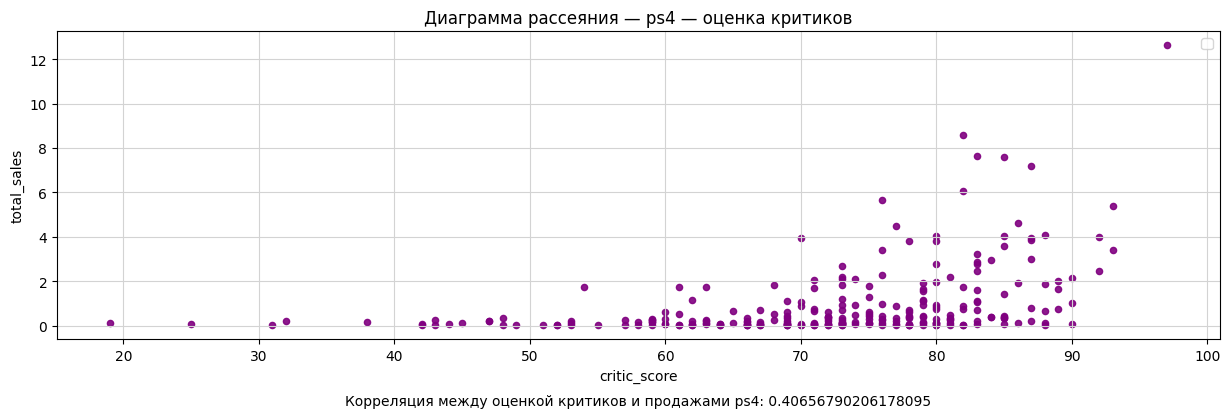

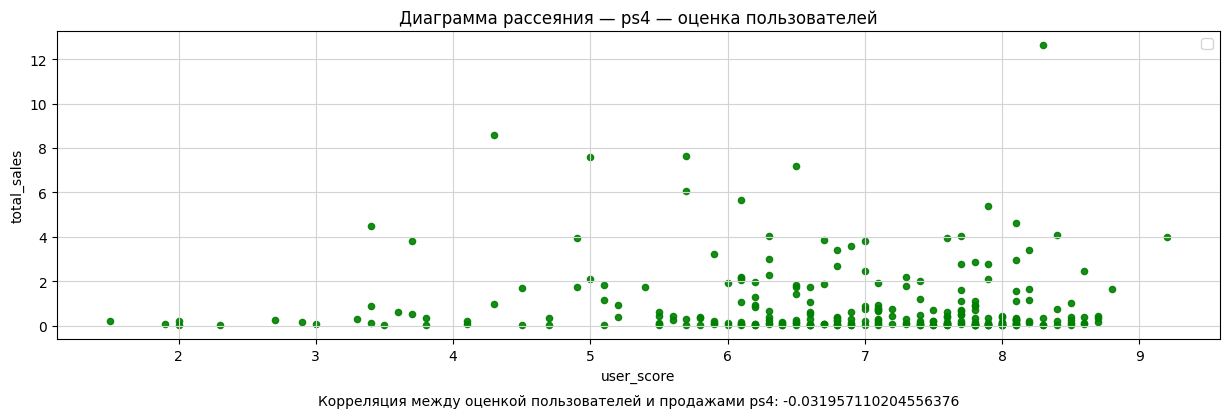

In [43]:
# оценка критиков
df_last3_act[df_last3_act['platform'] == 'ps4'].query('critic_score > 0').plot(kind='scatter',
        y='total_sales' , x='critic_score', alpha=0.9, subplots=True, figsize=(15,4), color='purple', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — ps4 — оценка критиков');
ps4_cr_corr = (df_last3_act
               .query('platform == "ps4" and critic_score > 0')['critic_score']
               .corr(df_last3_act.query('platform == "ps4" and critic_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой критиков и продажами ps4: {ps4_cr_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

# оценка пользователей
df_last3_act[df_last3_act['platform'] == 'ps4'].query('user_score > 0').plot(kind='scatter',
        y='total_sales' , x='user_score', alpha=0.9, subplots=True, figsize=(15,4), color='green', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — ps4 — оценка пользователей');
ps4_us_corr = (df_last3_act
               .query('platform == "ps4" and user_score > 0')['user_score']
               .corr(df_last3_act.query('platform == "ps4" and user_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой пользователей и продажами ps4: {ps4_us_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

#### ps3

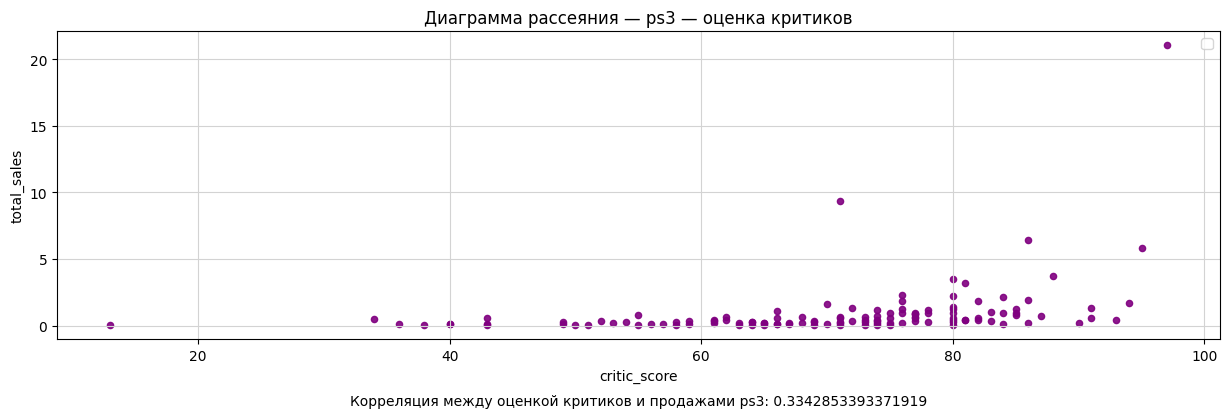

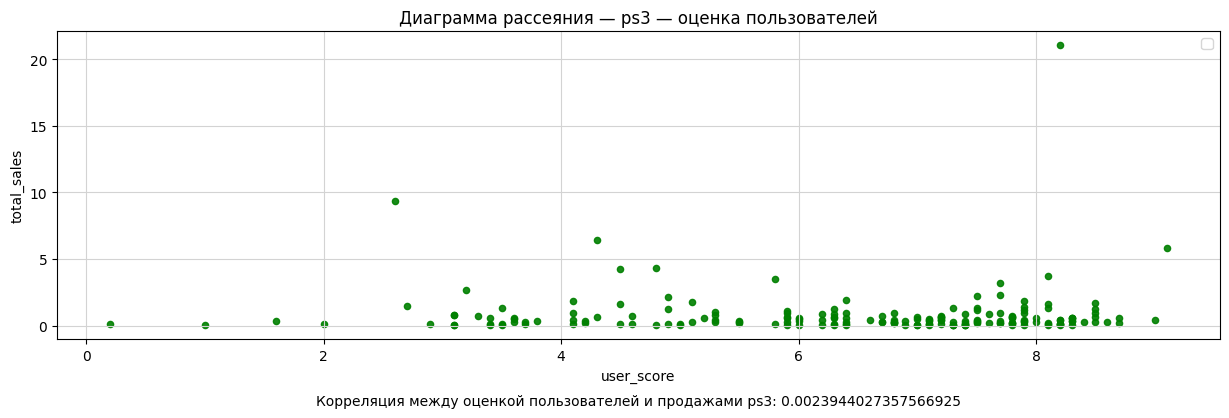

In [44]:
# оценка критиков
df_last3_act[df_last3_act['platform'] == 'ps3'].query('critic_score > 0').plot(kind='scatter',
        y='total_sales' , x='critic_score', alpha=0.9, subplots=True, figsize=(15,4), color='purple', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — ps3 — оценка критиков');
ps3_cr_corr = (df_last3_act
               .query('platform == "ps3" and critic_score > 0')['critic_score']
               .corr(df_last3_act.query('platform == "ps3" and critic_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой критиков и продажами ps3: {ps3_cr_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);


# оценка пользователей
df_last3_act[df_last3_act['platform'] == 'ps3'].query('user_score > 0').plot(kind='scatter',
        y='total_sales' , x='user_score', alpha=0.9, subplots=True, figsize=(15,4), color='green', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — ps3 — оценка пользователей');
ps3_us_corr = (df_last3_act
               .query('platform == "ps3" and user_score > 0')['user_score']
               .corr(df_last3_act.query('platform == "ps3" and user_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой пользователей и продажами ps3: {ps3_us_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

#### x360

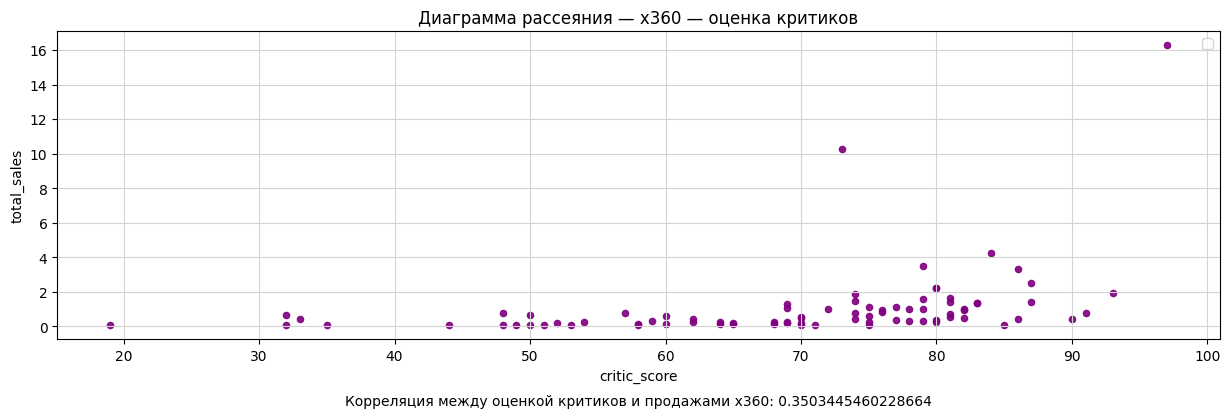

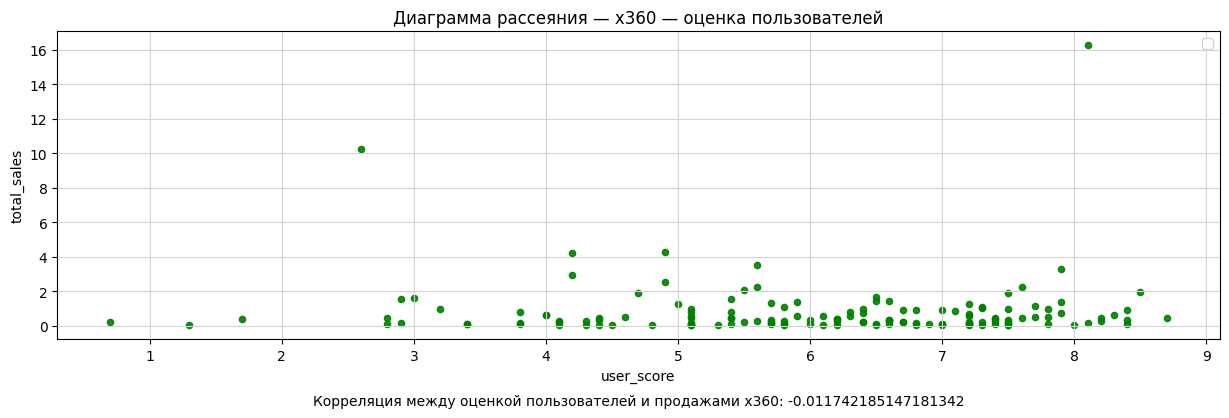

In [45]:
# оценка критиков
df_last3_act[df_last3_act['platform'] == 'x360'].query('critic_score > 0').plot(kind='scatter',
        y='total_sales' , x='critic_score', alpha=0.9, subplots=True, figsize=(15,4), color='purple', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — x360 — оценка критиков');
x360_cr_corr = (df_last3_act
               .query('platform == "x360" and critic_score > 0')['critic_score']
               .corr(df_last3_act.query('platform == "x360" and critic_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой критиков и продажами x360: {x360_cr_corr}', ha='center', va='center', transform=plt.gca().transAxes);


# оценка пользователей
df_last3_act[df_last3_act['platform'] == 'x360'].query('user_score > 0').plot(kind='scatter',
        y='total_sales' , x='user_score', alpha=0.9, subplots=True, figsize=(15,4), color='green', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — x360 — оценка пользователей');
x360_us_corr = (df_last3_act
               .query('platform == "x360" and user_score > 0')['user_score']
               .corr(df_last3_act.query('platform == "x360" and user_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой пользователей и продажами x360: {x360_us_corr}', ha='center', va='center', transform=plt.gca().transAxes);

#### 3ds

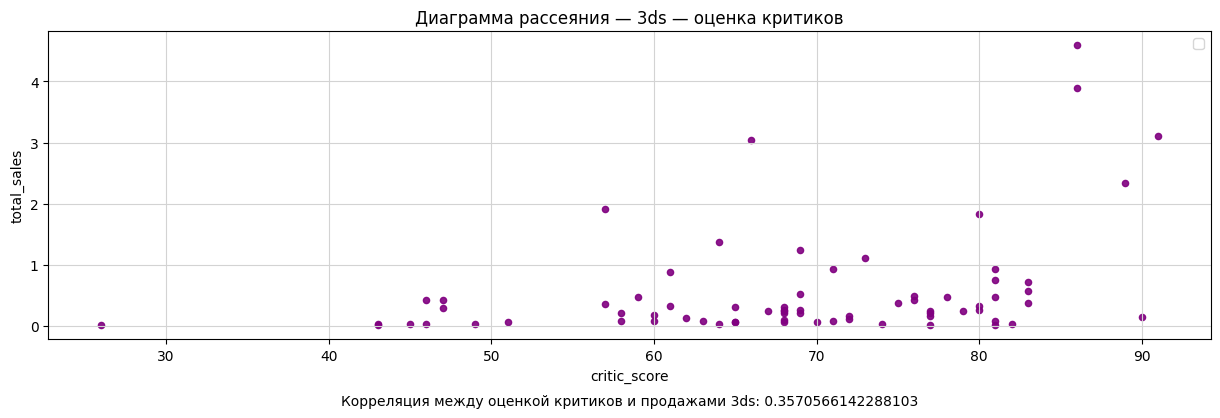

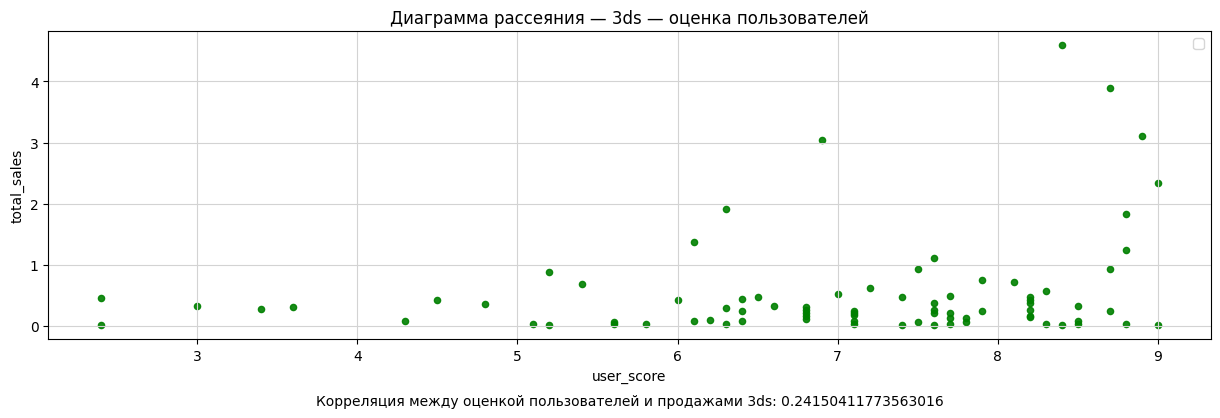

In [46]:
# оценка критиков
df_last3_act[df_last3_act['platform'] == '3ds'].query('critic_score > 0').plot(kind='scatter',
        y='total_sales' , x='critic_score', alpha=0.9, subplots=True, figsize=(15,4), color='purple', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — 3ds — оценка критиков');
ds_cr_corr = (df_last3_act
               .query('platform == "3ds" and critic_score > 0')['critic_score']
               .corr(df_last3_act.query('platform == "3ds" and critic_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой критиков и продажами 3ds: {ds_cr_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

# оценка пользователей
df_last3_act[df_last3_act['platform'] == '3ds'].query('user_score > 0').plot(kind='scatter',
        y='total_sales' , x='user_score', alpha=0.9, subplots=True, figsize=(15,4), color='green', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — 3ds — оценка пользователей');
ds_us_corr = (df_last3_act
               .query('platform == "3ds" and user_score > 0')['user_score']
               .corr(df_last3_act.query('platform == "3ds" and user_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой пользователей и продажами 3ds: {ds_us_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

#### xone

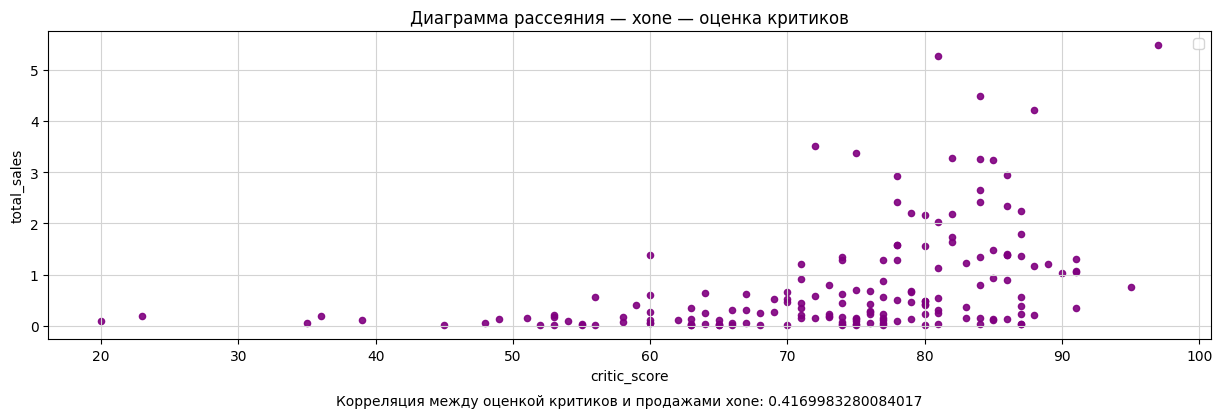

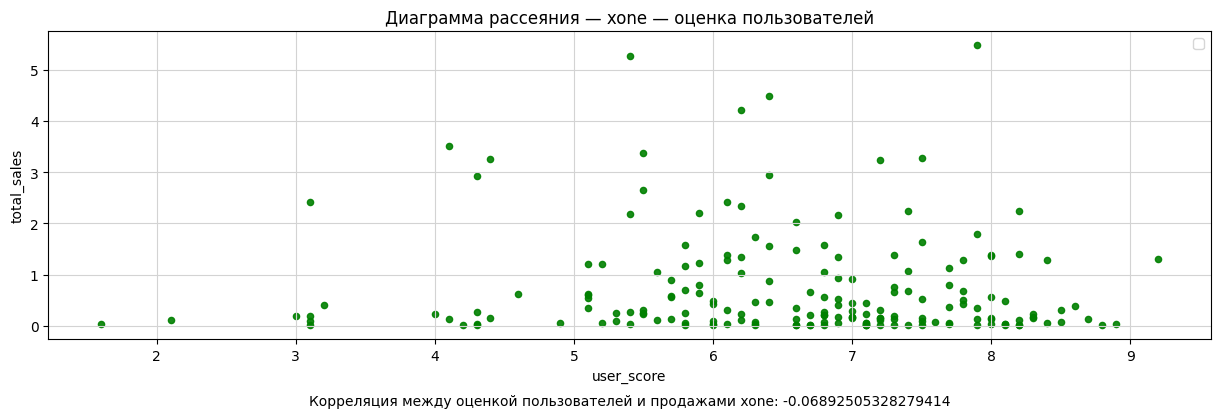

In [47]:
# оценка критиков
df_last3_act[df_last3_act['platform'] == 'xone'].query('critic_score > 0').plot(kind='scatter',
        y='total_sales' , x='critic_score', alpha=0.9, subplots=True, figsize=(15,4), color='purple', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — xone — оценка критиков');
xone_cr_corr = (df_last3_act
               .query('platform == "xone" and critic_score > 0')['critic_score']
               .corr(df_last3_act.query('platform == "xone" and critic_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой критиков и продажами xone: {xone_cr_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

# оценка пользователей
df_last3_act[df_last3_act['platform'] == 'xone'].query('user_score > 0').plot(kind='scatter',
        y='total_sales' , x='user_score', alpha=0.9, subplots=True, figsize=(15,4), color='green', s=20, grid=True)
plt.grid(color='lightgrey')
plt.title('Диаграмма рассеяния — xone — оценка пользователей');
xone_us_corr = (df_last3_act
               .query('platform == "xone" and user_score > 0')['user_score']
               .corr(df_last3_act.query('platform == "xone" and user_score > 0')['total_sales'])
              )
plt.text(0.5, -0.2, f'Корреляция между оценкой пользователей и продажами xone: {xone_us_corr}', 
         ha='center', va='center', transform=plt.gca().transAxes);

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

### Распределение игр по жанрам

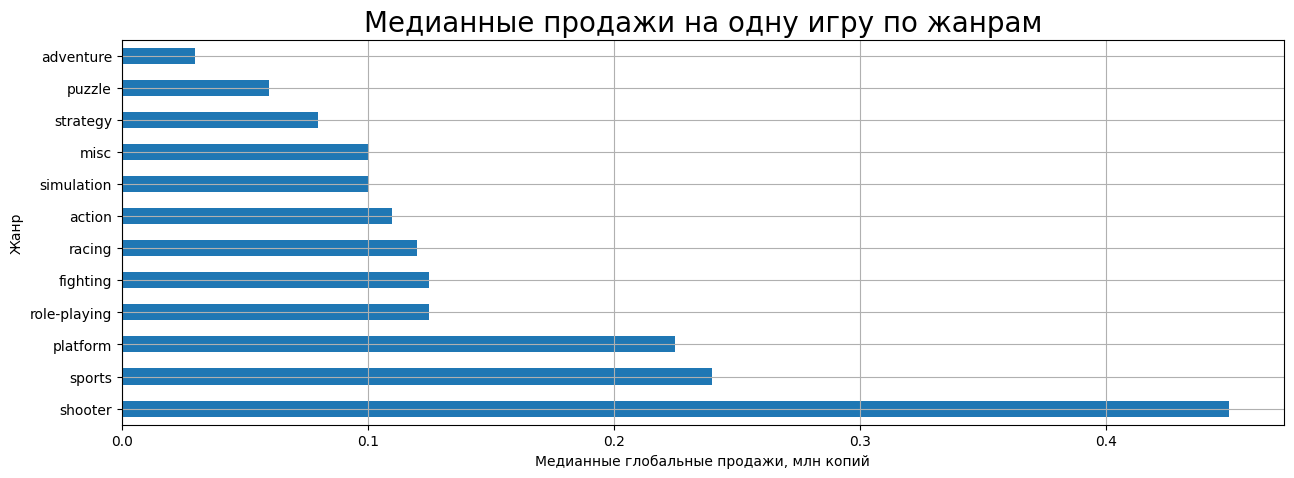

In [48]:
# построим график - посмотрим, какую прибыль приносит каждый жанр
(
    df_last3_act
    .pivot_table(index='genre', values='total_sales', aggfunc='median')
    .sort_values(by='total_sales', ascending=False)
    .plot(kind='barh', figsize=(15, 5), legend=False, grid=True)
);

plt.title('Медианные продажи на одну игру по жанрам', fontsize=20, color='black')
plt.xlabel('Медианные глобальные продажи, млн копий')
plt.ylabel('Жанр');

/tmp/ipykernel_1805/2093011764.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


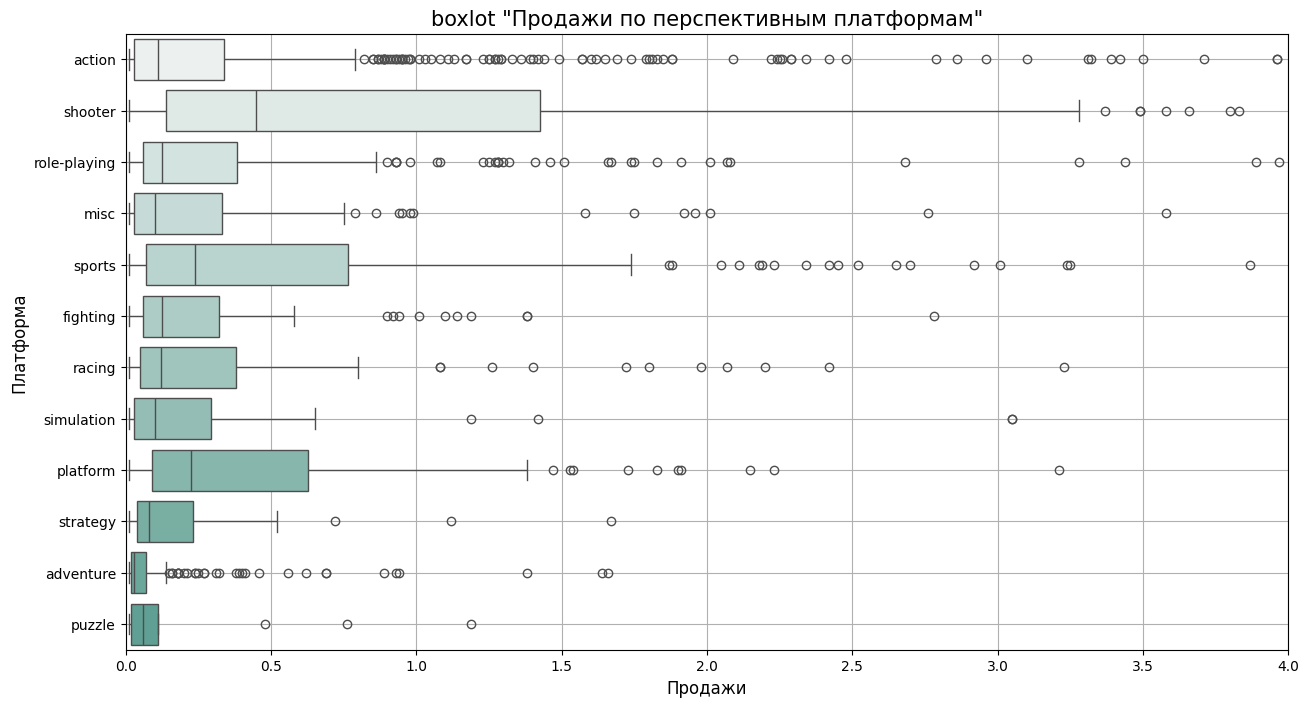

In [49]:
fig, ax = plt.subplots(figsize=(15,8))

sns.boxplot(
    data=df_last3_act,
    x='total_sales', 
    y='genre', 
    palette="light:#5A9"
)

plt.title('boxlot "Продажи по перспективным платформам"', fontsize=15)
plt.xlabel('Продажи', fontsize=12)
plt.ylabel('Платформа',fontsize=12)
plt.xlim(0, 4)

plt.grid(True)
plt.show()

/tmp/ipykernel_1805/2617383134.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


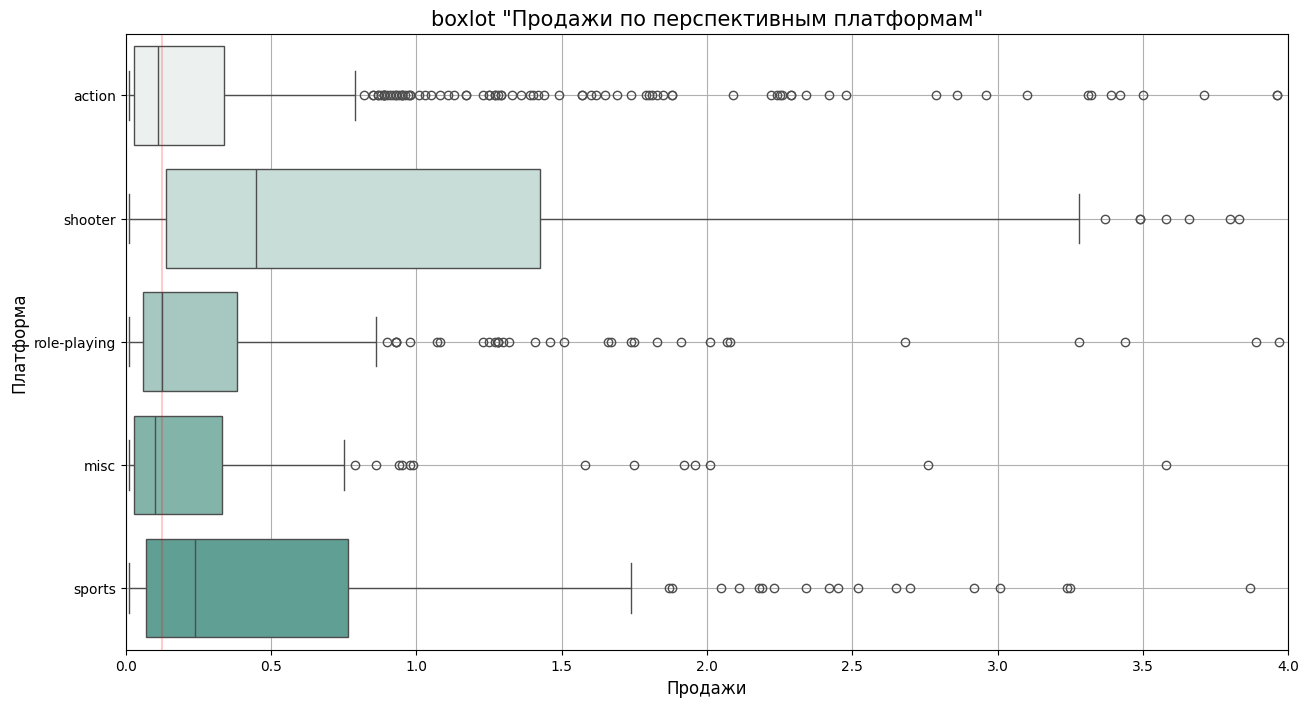

In [50]:
# Выведем топ-5 жанров
top5_genres = df_last3_act.groupby('genre')['total_sales'].sum().nlargest(5).index

fig, ax = plt.subplots(figsize=(15,8))

sns.boxplot(
    data=df_last3_act[df_last3_act['genre'].isin(top5_genres)],
    x='total_sales', 
    y='genre', 
    palette="light:#5A9"
)

plt.title('boxlot "Продажи по перспективным платформам"', fontsize=15)
plt.xlabel('Продажи', fontsize=12)
plt.ylabel('Платформа',fontsize=12)
plt.xlim(0, 4)
plt.axvline(x=0.125, color='red', linestyle='-', alpha=0.2)

plt.grid(True)
plt.show()

In [51]:
"""# посмотрим на количество игр каждого жанра

act_df['genre'].value_counts().plot(kind='barh', figsize=(15, 5), legend=False, grid=True);
plt.xlabel('Игр всего')
plt.ylabel('Жанр');"""

"# посмотрим на количество игр каждого жанра\n\nact_df['genre'].value_counts().plot(kind='barh', figsize=(15, 5), legend=False, grid=True);\nplt.xlabel('Игр всего')\nplt.ylabel('Жанр');"

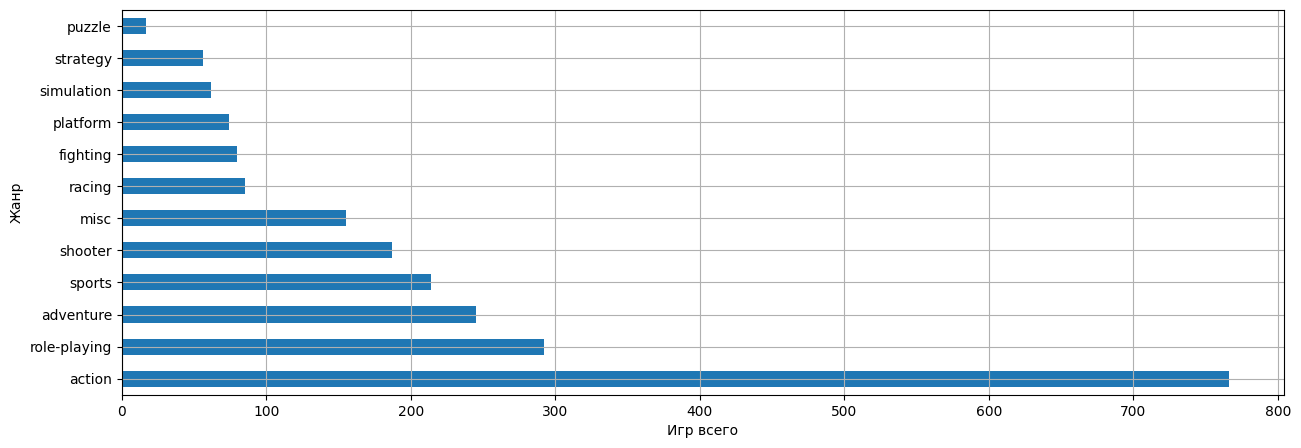

In [52]:
# посмотрим на количество игр каждого жанра

df_last3_act['genre'].value_counts().plot(kind='barh', figsize=(15, 5), legend=False, grid=True);
plt.xlabel('Игр всего')
plt.ylabel('Жанр');

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

## Портрет пользователя

Определим для пользователя каждого региона (NA, EU, JP):
- Самые популярные платформы (топ-5)
- Самые популярные жанры (топ-5)
- Влияет ли рейтинг ESRB на продажи в отдельном регионе?


### Самые популярные платформы

Создадим функцию, чтобы упростить построение графиков по каждому региону - по продажам топ-5

In [53]:
# функция для построения графиков pie

def visual_pie(df, title = [], xlab = [], ylab =[]):
    df.plot(kind='pie', subplots=True, legend=False, autopct='%.2f%%')
    plt.title(title)
    plt.xlabel(xlab)
    plt.ylabel(ylab)
    return 

,na_sales
platform,
ps4,108.74
xone,93.12
x360,81.66
ps3,63.50
3ds,38.20


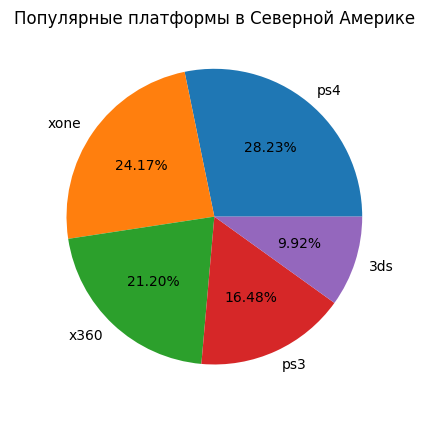

In [54]:
# посмотрим на топ-5 платформ в Северной Америке
na = act_piv_top(df_last3_act, 'platform', 'na_sales', 'sum')
display(na)
visual_pie(na, 'Популярные платформы в Северной Америке', ' ', ' ');

,eu_sales
platform,
ps4,141.09
ps3,67.81
xone,51.59
x360,42.52
3ds,30.96


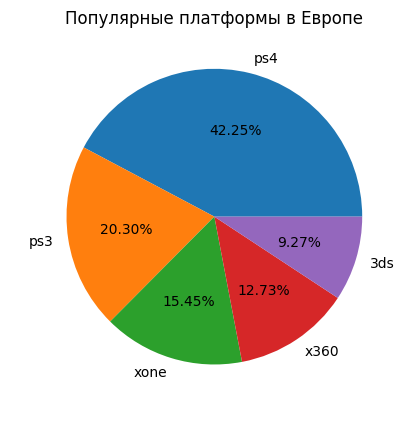

In [55]:
# посмотрим на топ-5 платформ в Европе
eu = act_piv_top(df_last3_act, 'platform', 'eu_sales', 'sum')
display(eu)
visual_pie(eu, 'Популярные платформы в Европе', ' ', ' ');

,jp_sales
platform,
3ds,67.81
ps3,23.35
psv,18.59
ps4,15.96
wiiu,10.88


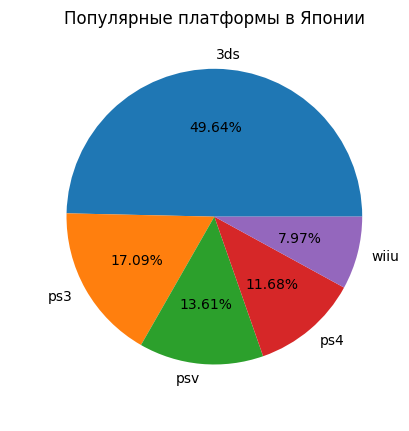

In [56]:
# выведем топ-5 платформ в Японии
jp = act_piv_top(df_last3_act, 'platform', 'jp_sales', 'sum')
display(jp)
visual_pie(jp, 'Популярные платформы в Японии', ' ', ' ');

Вывод:
Среди топ-5 платформ в каждом регионе лидирует:
- Северная Америка: ps4 - чуть больше четверти. На пятки наступают конкуренты из Microsoft: x360 - 23.54%, xone - 22.92%
- Европа: больше половины приходится на платформу ps - больше трети рынка за ps4, еще почти четверть за ps3, x360 не так популярен, как в Северной Америке
- Япония: подавляющее большинство за 3ds, еще почти 1/5 - ps3, консоли Microsoft не пользуются большой популярностью, в рейтинге их нет

### Самые популярные жанры

Аналолично прошлому шагу, построим графики по каждому региону - по жанрам топ-5

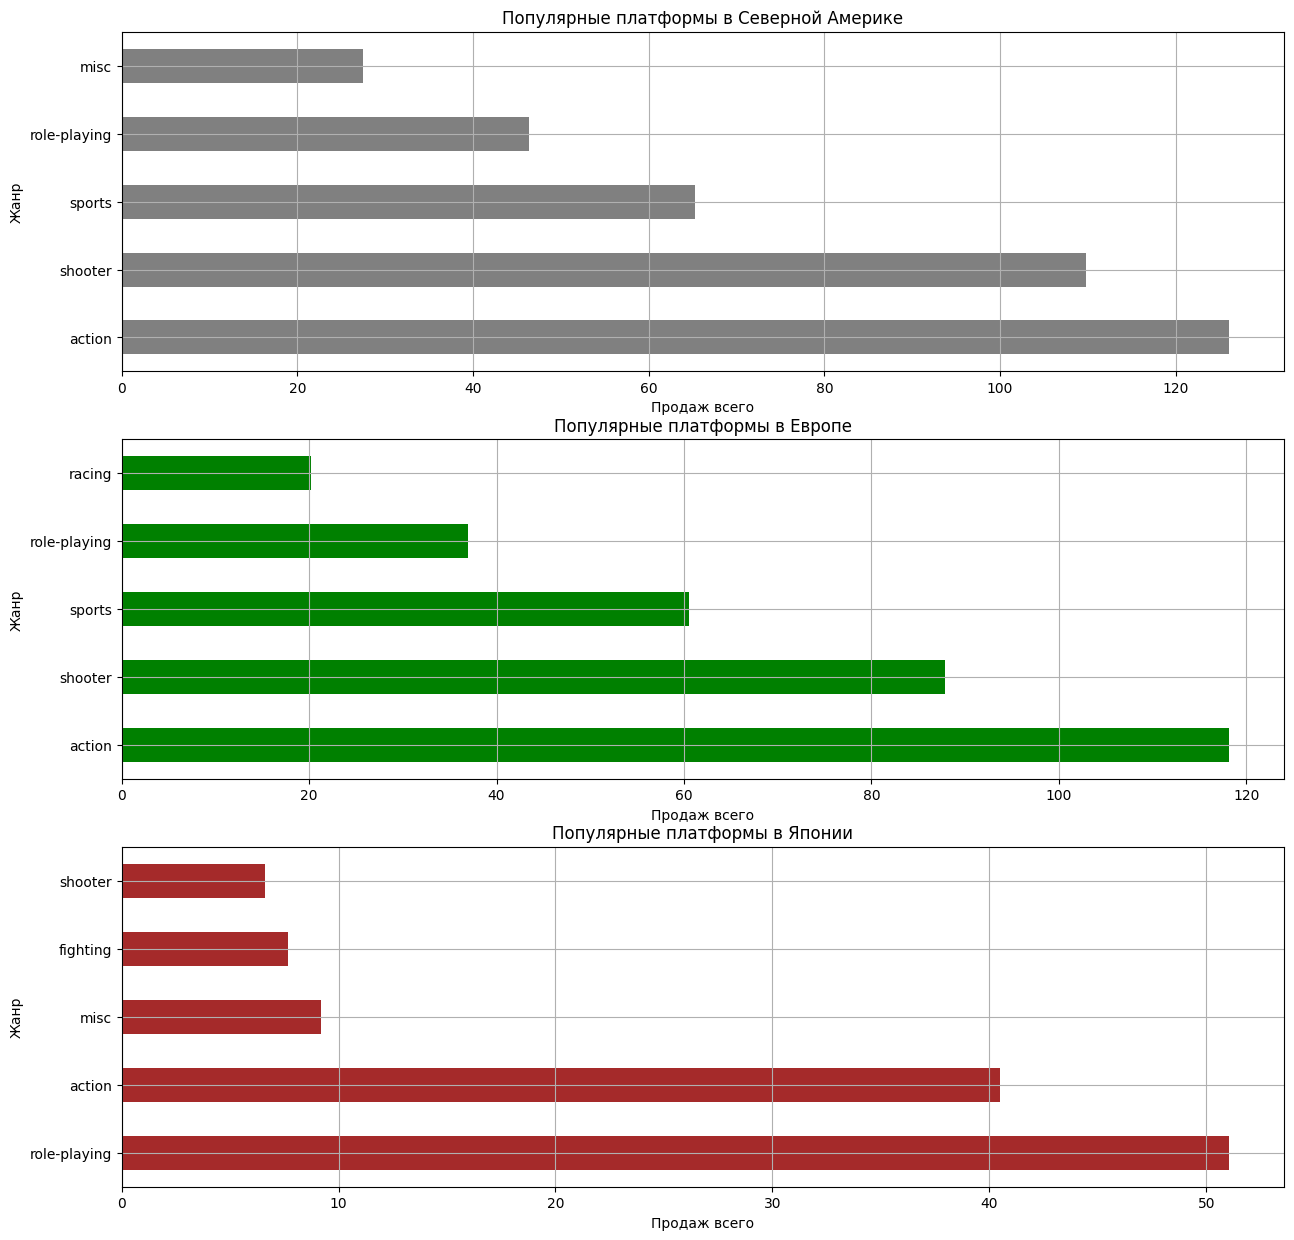

In [57]:
# переменые:
# na_sales
na_genre = act_piv_top(df_last3_act, 'genre', 'na_sales', 'sum')

# eu_sales
eu_genre = act_piv_top(df_last3_act, 'genre', 'eu_sales', 'sum')

# jp_sales
jp_genre = act_piv_top(df_last3_act, 'genre', 'jp_sales', 'sum')



# покажем наглядно
fig, ax = plt.subplots(3, 1, figsize=(15, 15))

# график для na_sales
na_genre.plot(kind='barh', ax=ax[0], legend=False, grid=True, color='grey')
ax[0].set_title('Популярные платформы в Северной Америке')
ax[0].set_xlabel('Продаж всего')
ax[0].set_ylabel('Жанр')

# график для eu_sales
eu_genre.plot(kind='barh', ax=ax[1], legend=False, grid=True, color='green')
ax[1].set_title('Популярные платформы в Европе')
ax[1].set_xlabel('Продаж всего')
ax[1].set_ylabel('Жанр')

# график для jp_sales
jp_genre.plot(kind='barh', ax=ax[2], legend=False, grid=True, color='brown')
ax[2].set_title('Популярные платформы в Японии')
ax[2].set_xlabel('Продаж всего')
ax[2].set_ylabel('Жанр')

plt.show()

Выводы:
- В Северной Америке и Европе предпочтения пользователей полностью совпадают;
- В Японии жанром action также интересуются, но меньше в процентром соотношении. Тут категория №1 - это role-playing.

### Рейтинг ESRB

,na_sales
rating,
M,165.21
E,79.05
E10+,54.24
T,49.79


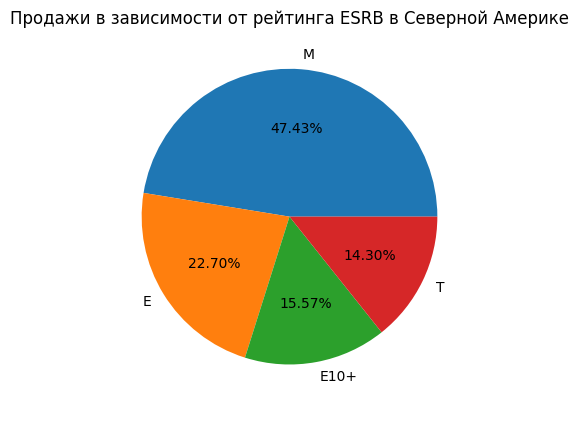

In [58]:
# посмотрим на топ-5 платформ в Северной Америке
na_ratings = act_piv_top(df_last3_act, 'rating', 'na_sales', 'sum')
display(na_ratings)
visual_pie(na_ratings, 'Продажи в зависимости от рейтинга ESRB в Северной Америке', ' ', ' ');

Практически половина покупаемых игр - для категории "от 17 лет" - 48%. Еще 22% составляет категория "Для всех" 

,eu_sales
rating,
M,145.32
E,83.36
E10+,42.69
T,41.95


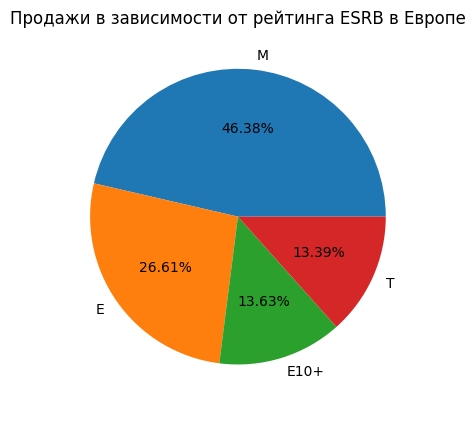

In [59]:
# топ-5 платформ в Европе
eu_ratings = act_piv_top(df_last3_act, 'rating', 'eu_sales', 'sum')
display(eu_ratings)
visual_pie(eu_ratings, 'Продажи в зависимости от рейтинга ESRB в Европе', ' ', ' ');

Соотношение игр аналогично соотношению в СА: в Европе также порядка половины покупаемых игр - для категории "от 17 лет". Еще 26% составляет категория "Для всех" 

,jp_sales
rating,
T,20.59
E,15.14
M,14.11
E10+,5.89


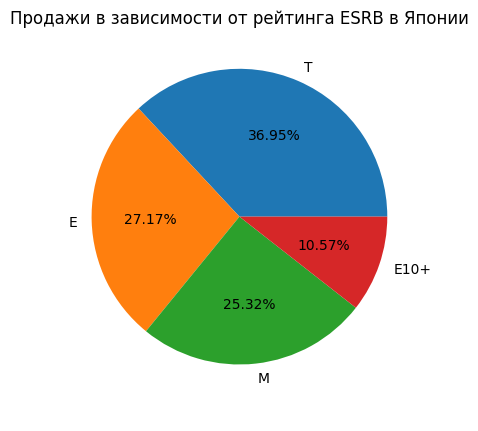

In [60]:
# топ-5 платформ в Японии
jp_ratings = act_piv_top(df_last3_act, 'rating', 'jp_sales', 'sum')
display(jp_ratings)
visual_pie(jp_ratings, 'Продажи в зависимости от рейтинга ESRB в Японии', ' ', ' ');

В отличие от предыдущих двух рынком, тут ситуация совершенно другая: более трети игр относится к категории "Подростки", еще 28% покупается в категории "Для всех". Категория "от 17 лет" стоит только на 3ем месте с 25%. 

Посмотрим на типичных пользователей по регионам:

In [61]:
# Северная Америка
act_piv_top(df_last3_act, ['platform', 'genre', 'rating'], ['na_sales'], 'sum')

,,,na_sales
platform,genre,rating,
xone,shooter,M,22.40
x360,shooter,M,18.69
ps4,action,M,18.16
x360,action,M,17.61
ps3,action,M,17.04


Несмотря на растущую популярность новых платформ, в СА пока еще актуальны lastgen консоли - x360 и ps3. Видно, что новое поколение подбирается совсем близко. Предположительно уже по итогам 2016 мы увидим, что nextgen впереди. Наиболее популярные жанры - shooter и action

In [62]:
# Европа
act_piv_top(df_last3_act, ['platform', 'genre', 'rating'], ['eu_sales'], 'sum')

eu_sales
platform genre   rating          
ps4      action  M          26.03
         sports  E          22.26
         shooter M          21.86
ps3      action  M          18.80
         sports  E          11.58

В отличие от СА, в Европе ps4 уже набрала хороший ход. Пользователи предпочитают играть в жанры action, shooter и sports. ps3 пока еще держится на плаву, но есть основание полагать, что как и в СА новое поколение консолей выйдет в топ окончательно

In [63]:
# Япония
act_piv_top(df_last3_act, ['platform', 'genre', 'rating'], ['jp_sales'], 'sum')

,,,jp_sales
platform,genre,rating,
3ds,role-playing,T,4.22
ps3,action,M,3.60
psv,role-playing,T,2.87
ps3,role-playing,T,2.72
3ds,action,E,2.48


В Японии пользователь своеобразный и не падкий свежие новинки. Особое внимание заслуживают портативные консоли: 3ds и psv. Возможно, это связано с нежеланием и/или невозможностью провести спокойно время дома у телевизора. Возможно, для этого рынка потребуется еще год-два, чтобы платформы нового поколения вышли в топ

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.

## Гипотезы

### О рейтингах Xbox One и PC

Средние пользовательские рейтинги платформ Xbox One и PC одинаковые

**H0: Средние пользовательские рейтинги Xbox One = Средние пользовательские рейтинги PC**

**H1: Средние пользовательские рейтинги Xbox One != Средние пользовательские рейтинги PC**

In [64]:
alpha = 0.01

# Сравниваем рейтинги за единый актуальный для проекта период: 2013–2016.
# Исключаем пропущенные оценки, используем Welch t-test (дисперсии не считаем равными).
avg_xone = df_last3_act.loc[(df_last3_act["platform"] == "xone"), "user_score"].dropna()
avg_pc = df_last3_act.loc[(df_last3_act["platform"] == "pc"), "user_score"].dropna()

results51 = st.ttest_ind(avg_xone, avg_pc, equal_var=False, alternative="two-sided")
print(f"p-value: {results51.pvalue:.6g}")
if results51.pvalue < alpha:
    print("Отвергаем H0: есть статистически значимые основания считать средние рейтинги разными.")
else:
    print("Не отвергаем H0: данных недостаточно, чтобы заключить, что средние рейтинги различаются.")

p-value: 0.147596
Не отвергаем H0: данных недостаточно, чтобы заключить, что средние рейтинги различаются.


Не отвергаем H₀ при α = 0,01: на данных 2013–2016 годов недостаточно оснований утверждать, что средние пользовательские рейтинги Xbox One и PC различаются. Это не доказывает равенство средних.

### О рейтингах Action и Sports

Средние пользовательские рейтинги жанров Action и Sports разные

**H0: Средние пользовательские рейтинги жанра Action = Средние пользовательские рейтинги жанра Sports**

**H1: Средние пользовательские рейтинги жанра Action != Средние пользовательские рейтинги жанра Sports**

In [65]:
alpha = 0.01

# Сравниваем рейтинги жанров за период 2013–2016; пропущенные оценки исключаем.
avg_action = df_last3_act.loc[df_last3_act["genre"] == "action", "user_score"].dropna()
avg_sports = df_last3_act.loc[df_last3_act["genre"] == "sports", "user_score"].dropna()

results52 = st.ttest_ind(avg_action, avg_sports, equal_var=False, alternative="two-sided")
print(f"p-value: {results52.pvalue:.6g}")
if results52.pvalue < alpha:
    print("Отвергаем H0: есть статистически значимые основания считать средние рейтинги разными.")
else:
    print("Не отвергаем H0: данных недостаточно, чтобы заключить, что средние рейтинги различаются.")

p-value: 1.446e-20
Отвергаем H0: есть статистически значимые основания считать средние рейтинги разными.


Не отвергаем H₀ при α = 0,01: на данных 2013–2016 годов недостаточно оснований утверждать, что средние пользовательские рейтинги Xbox One и PC различаются. Это не доказывает равенство средних.

## Итоговые выводы

Это ретроспективный анализ исторических данных о продажах игр до 2016 года; результаты не описывают современный рынок.

- Подготовлены данные: названия столбцов приведены к нижнему регистру, типы данных проверены, значения `tbd` преобразованы в пропуски, удалены записи без названия и дубликаты по сочетанию игры, платформы и года.
- Для сравнения платформ и жанров используется единый период 2013–2016 годов. Продажи анализируются в миллионах проданных копий, а не в денежной выручке.
- Корреляция оценок с продажами показывает связь, но не доказывает, что оценки вызывают увеличение продаж.
- При α = 0,01 тест Welch не выявил статистически значимого различия средних пользовательских рейтингов Xbox One и PC (p-value ≈ 0,148). Для жанров Action и Sports различие оказалось статистически значимым (p-value ≈ 1,45 × 10⁻²⁰). Статистическая значимость сама по себе не говорит о размере или практической важности эффекта.

**Практический смысл:** в рамках учебного кейса можно сравнить исторические платформы, жанры и региональные предпочтения. Любые рекомендации по закупкам или рекламе требуют более свежих данных и учёта контекста рынка.